<a href="https://colab.research.google.com/github/robertbarcik/vector_databases-tutorial/blob/main/4.%20Graph_Databases/2_graphrag_neo4j.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# GraphRAG: a Language Model Builds the Graph

In the previous notebook the graph came from a clean JSON file: someone had already decided that Sarah `MANAGES` Marcus. Real knowledge lives in meeting notes, design documents and announcements, where the same fact is a sentence: "Marcus will be leading the deployment effort".

This notebook lets a language model read six such documents and **extract the entities and relationships** into a Neo4j graph, then stores the same documents as vectors in Chroma, and finally answers questions three ways: **vector only** (the RAG you know), **graph only** (Cypher), and **both together**. The last one is GraphRAG, and the comparison shows what each side sees that the other cannot.


## Setup: a Neo4j server

Neo4j is a server, not a library. On **Colab** the cell below downloads Neo4j Community Edition (the 5.26 long-term-support line) and starts it inside the runtime; it takes about a minute and needs no account. On your **own machine** skip the download and run Neo4j in Docker before you continue:

```
docker run -d --name neo4j -p 7474:7474 -p 7687:7687 -e NEO4J_AUTH=neo4j/password123 neo4j:5.26-community
```

Either way the notebook talks to `bolt://localhost:7687` with user `neo4j` and password `password123`.


In [1]:
import os, sys, time, socket, subprocess, pathlib

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def bolt_ready(host="127.0.0.1", port=7687):
    with socket.socket() as s:
        s.settimeout(1)
        return s.connect_ex((host, port)) == 0

if IN_COLAB and not pathlib.Path("neo4j").exists():
    print("Installing Java 17 and Neo4j 5.26.30 (about a minute) ...")
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jre-headless wget", shell=True, capture_output=True)
    subprocess.run("wget -q https://dist.neo4j.org/neo4j-community-5.26.30-unix.tar.gz && "
                   "tar -xf neo4j-community-5.26.30-unix.tar.gz && mv neo4j-community-5.26.30 neo4j", shell=True, check=True)
    subprocess.run("neo4j/bin/neo4j-admin dbms set-initial-password password123", shell=True, capture_output=True)
    subprocess.run("neo4j/bin/neo4j start", shell=True, capture_output=True)

if IN_COLAB and not bolt_ready():
    subprocess.run("neo4j/bin/neo4j start", shell=True, capture_output=True)

for _ in range(45):
    if bolt_ready():
        break
    time.sleep(2)

print("Neo4j reachable on bolt://localhost:7687:", bolt_ready(),
      "" if IN_COLAB else "(local machine: start the Docker container above if this says False)")


Neo4j reachable on bolt://localhost:7687: True (local machine: start the Docker container above if this says False)


Python side: the Neo4j driver, Chroma for the vectors, the OpenAI SDK for extraction, embeddings and answers, `pydantic` for the extraction schema. The model is `gpt-6-luna`; extracting six documents costs about a cent.


In [2]:
%pip install -q neo4j==6.4.1 chromadb==1.5.9 openai==3.51.0 pydantic networkx==3.7 matplotlib   # Colab installs here; locally, requirements.txt already covers it

import os, json, pathlib, urllib.request
from typing import Literal, Optional
from pydantic import BaseModel
from openai import OpenAI
from neo4j import GraphDatabase
import networkx as nx
import matplotlib.pyplot as plt

def colab_secret(name):
    """The key from Colab secrets, or None when we are not in Colab or there is no such secret."""
    try:
        from google.colab import userdata
        for attempt in range(12):                   # Colab shows a "Grant access" dialog the first time and waits only
            try:                                    # 10 seconds for your click. We keep asking for about two minutes.
                return userdata.get(name)
            except userdata.TimeoutException:
                pass
    except Exception:
        pass

# Your key, looked up in this order: Colab secret -> environment variable -> a prompt.
api_key = colab_secret("OPENAI_API_KEY") or os.environ.get("OPENAI_API_KEY")
while not isinstance(api_key, str) or not api_key.strip():   # nothing found: type it in
    from getpass import getpass
    typed = getpass("OpenAI API key: ")
    api_key = typed if isinstance(typed, str) else colab_secret("OPENAI_API_KEY")   # a late click on "Grant access" lands here: read the secret again
api_key = api_key.strip()                           # a pasted key often ends with a newline; the API rejects that header

client = OpenAI(api_key=api_key)
MODEL = "gpt-6-luna"
EMBEDDING_MODEL = "text-embedding-3-small"

try:                                                # one tiny request now, so a wrong key fails here with a clear message
    client.responses.create(model=MODEL, input="Say OK.", max_output_tokens=16)
except Exception as error:
    raise RuntimeError(f"The test request to OpenAI failed: {type(error).__name__}: {error}\n"
                       "Check the key (in Colab: the key icon on the left, secret OPENAI_API_KEY) and run this cell again.") from None

RAW = "https://raw.githubusercontent.com/robertbarcik/vector_databases-tutorial/main/4.%20Graph_Databases/"
if not pathlib.Path("sample_documents.json").exists():
    urllib.request.urlretrieve(RAW + "sample_documents.json", "sample_documents.json")

driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", "password123"))
driver.verify_connectivity()

def run(query, **params):
    with driver.session() as session:
        return [dict(r) for r in session.run(query, **params)]

os.environ["ANONYMIZED_TELEMETRY"] = "False"
import chromadb
from chromadb.utils import embedding_functions

print("Ready. Model:", MODEL, "| Neo4j connected")


Note: you may need to restart the kernel to use updated packages.


Ready. Model: gpt-6-luna | Neo4j connected


## 4.3 GraphRAG: a language model builds the graph

### When plain RAG is not enough

Vector search finds the passages that *sound like* the question. That is enough for "what did the fraud detection kickoff decide?", because one document holds the answer. It struggles when the answer is spread across documents and hangs on *connections*: "who works with people who work with Marcus?", "which projects share team members with the Stanford partnership?". Those need hops, and hops are what a graph does.

GraphRAG is the combination: vectors to find the right *entry points* in the text, the graph to walk outward from them, and one prompt that carries both.


### The documents

Six pieces of company writing: a team update, a technical design, kickoff notes, a paper, a quarterly review and a partnership announcement. Roughly a thousand words in total. Read one and notice how the facts hide in prose: nobody wrote "Marcus Johnson LEADS Fraud Detection System", the text says he "will serve as technical lead".


In [3]:
docs = json.load(open("sample_documents.json"))

for i, d in enumerate(docs, 1):
    print(f"{i}. {d['title']}  ({len(d['content'].split())} words)")

print("\n" + docs[2]["content"][:700], "...")


1. Q4 2024 AI Research Team Update  (114 words)
2. Recommendation Engine v2 - Technical Design  (140 words)
3. Fraud Detection System - Project Kickoff Notes  (147 words)
4. Research Paper: Deep Learning for Time Series Forecasting  (159 words)
5. Engineering Team Quarterly Review - Q4 2024  (186 words)
6. Partnership Announcement: TechCorp and Stanford AI Lab  (203 words)

Meeting Date: October 15, 2024
Attendees: Marcus Johnson, Robert Brown, James Liu, Amy Zhang (Senior Backend Engineer), Lisa Anderson (DevOps Engineer)

The Fraud Detection System project was initiated following a request from the Finance department. This critical project will use anomaly detection algorithms to identify suspicious transaction patterns in real-time.

Marcus Johnson will serve as technical lead, with Robert Brown focusing on model development. The system will be deployed on AWS infrastructure managed by Lisa Anderson. Amy Zhang will build the API layer for integration with our existing payment proces

### Extraction: from prose to entities and relationships

This is the step a person used to do by hand. We give the model a document and a **schema**: which kinds of entities we care about, which relationship types are allowed. With `responses.parse` and a Pydantic model (the structured-outputs technique from the previous course) the answer comes back as typed Python objects, never as JSON we have to clean up.

The schema is deliberately small. Five entity types, seven relationship types. A tighter vocabulary means a cleaner graph, and it is the most important design decision in the whole notebook.


In [4]:
class Entity(BaseModel):
    name: str                                            # one full name, no titles: "Sarah Chen", not "Dr. Sarah Chen"
    type: Literal["Person", "Organization", "Project", "Technology", "Event"]
    role: Optional[str]                                  # e.g. "Senior ML Engineer", "CEO"; null when unknown

class Relationship(BaseModel):
    source: str
    type: Literal["WORKS_ON", "LEADS", "COLLABORATES_WITH", "MEMBER_OF", "PARTNERS_WITH", "USES", "PRESENTED_AT"]
    target: str

class Extraction(BaseModel):
    entities: list[Entity]
    relationships: list[Relationship]

def extract(text):
    return client.responses.parse(
        model=MODEL,
        input=(
            "Extract the entities and the relationships between them from the document below. "
            "Use each person's full name without academic titles, the same spelling every time. "
            "Only include relationships that the text states or clearly implies.\n\nDOCUMENT:\n" + text
        ),
        text_format=Extraction,
    ).output_parsed

first = extract(docs[0]["content"])

print(f"{len(first.entities)} entities, {len(first.relationships)} relationships in '{docs[0]['title']}'\n")
for e in first.entities:
    print(f"  {e.type:<13} {e.name:<28} {e.role or ''}")
print()
for r in first.relationships:
    print(f"  {r.source} -[{r.type}]-> {r.target}")


13 entities, 13 relationships in 'Q4 2024 AI Research Team Update'

  Organization  AI Research team             
  Person        Sarah Chen                   Leader of the AI Research team
  Project       Customer Churn Prediction project 
  Person        Marcus Johnson               Senior ML Engineer
  Person        Priya Patel                  Data Scientist
  Organization  Data Engineering team        
  Person        Tom Wilson                   Head of the Data Engineering team
  Technology    transformer-based models     
  Event         NeurIPS 2024                 Conference
  Person        Andrew Ng                    
  Organization  Stanford University          
  Organization  Engineering department       
  Person        David Kim                    Leader of the Engineering department

  Sarah Chen -[LEADS]-> AI Research team
  Marcus Johnson -[MEMBER_OF]-> AI Research team
  Priya Patel -[MEMBER_OF]-> AI Research team
  AI Research team -[WORKS_ON]-> Customer Churn Pre

### 🔍 What just happened?

One call, one document, and the model returned typed objects: people with roles, the project, the conference, the university, and the edges between them. Look for the sentence "Marcus will be leading the deployment effort" in the text and find its edge in the list. Also look for what the model *chose not to* extract, and for any name that came back in two spellings; that is the classic failure of automatic graph building, and the reason for the "one full name, no titles" instruction.

Now all six documents. Each extraction also remembers which document it came from, so the graph can link entities to their sources.


In [5]:
extractions = []
for d in docs:
    ex = extract(d["content"])
    extractions.append((d["title"], ex))
    print(f"{len(ex.entities):>3} entities, {len(ex.relationships):>3} relationships  <- {d['title']}")

all_names = {e.name for _, ex in extractions for e in ex.entities}
print(f"\n{len(all_names)} distinct entity names across the six documents")


 13 entities,  12 relationships  <- Q4 2024 AI Research Team Update


 20 entities,  15 relationships  <- Recommendation Engine v2 - Technical Design


 17 entities,  11 relationships  <- Fraud Detection System - Project Kickoff Notes


 22 entities,  18 relationships  <- Research Paper: Deep Learning for Time Series Forecasting


 23 entities,  21 relationships  <- Engineering Team Quarterly Review - Q4 2024


 32 entities,  40 relationships  <- Partnership Announcement: TechCorp and Stanford AI Lab

85 distinct entity names across the six documents


### 🎯 Mini-task

Print the sorted list of entity names. Do you see the same person under two names? If so, add a `normalise(name)` function (strip "Dr." and "Prof.", fix the spelling) and apply it before the next step.


In [6]:
# YOUR CODE HERE


### Loading the extraction into Neo4j

Same recipe as the previous notebook, with one twist: `MERGE` instead of `CREATE`. Marcus Johnson appears in five documents; `MERGE` finds the existing node the second time instead of creating a duplicate. Every entity also gets a `MENTIONED_IN` edge to its document, which is the bridge we will need for the hybrid search.


In [7]:
run("MATCH (n) DETACH DELETE n")

for title, ex in extractions:
    run("MERGE (:Document {title: $title})", title=title)
    for e in ex.entities:
        run(f"MERGE (n:{e.type} {{name: $name}}) SET n.role = coalesce($role, n.role) "
            f"WITH n MATCH (d:Document {{title: $title}}) MERGE (n)-[:MENTIONED_IN]->(d)",
            name=e.name, role=e.role, title=title)
    for r in ex.relationships:
        run(f"MATCH (a {{name: $source}}), (b {{name: $target}}) MERGE (a)-[:{r.type}]->(b)",
            source=r.source, target=r.target)

for row in run("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS nodes ORDER BY nodes DESC"):
    print(f"{row['label']:<14} {row['nodes']}")
print()
for row in run("MATCH ()-[r]->() RETURN type(r) AS type, count(*) AS edges ORDER BY edges DESC"):
    print(f"{row['type']:<18} {row['edges']}")


Person         23
Technology     22
Project        18
Organization   16
Document       6
Event          6

MENTIONED_IN       127
WORKS_ON           40
USES               22
MEMBER_OF          19
COLLABORATES_WITH  19
LEADS              12
PRESENTED_AT       2
PARTNERS_WITH      1


Let's look at it. The picture is the payoff of the extraction step: a thousand words of prose became a navigable network. To keep it readable we draw only people, projects and organisations with at least two connections; technologies, events and the leaves stay in the database.


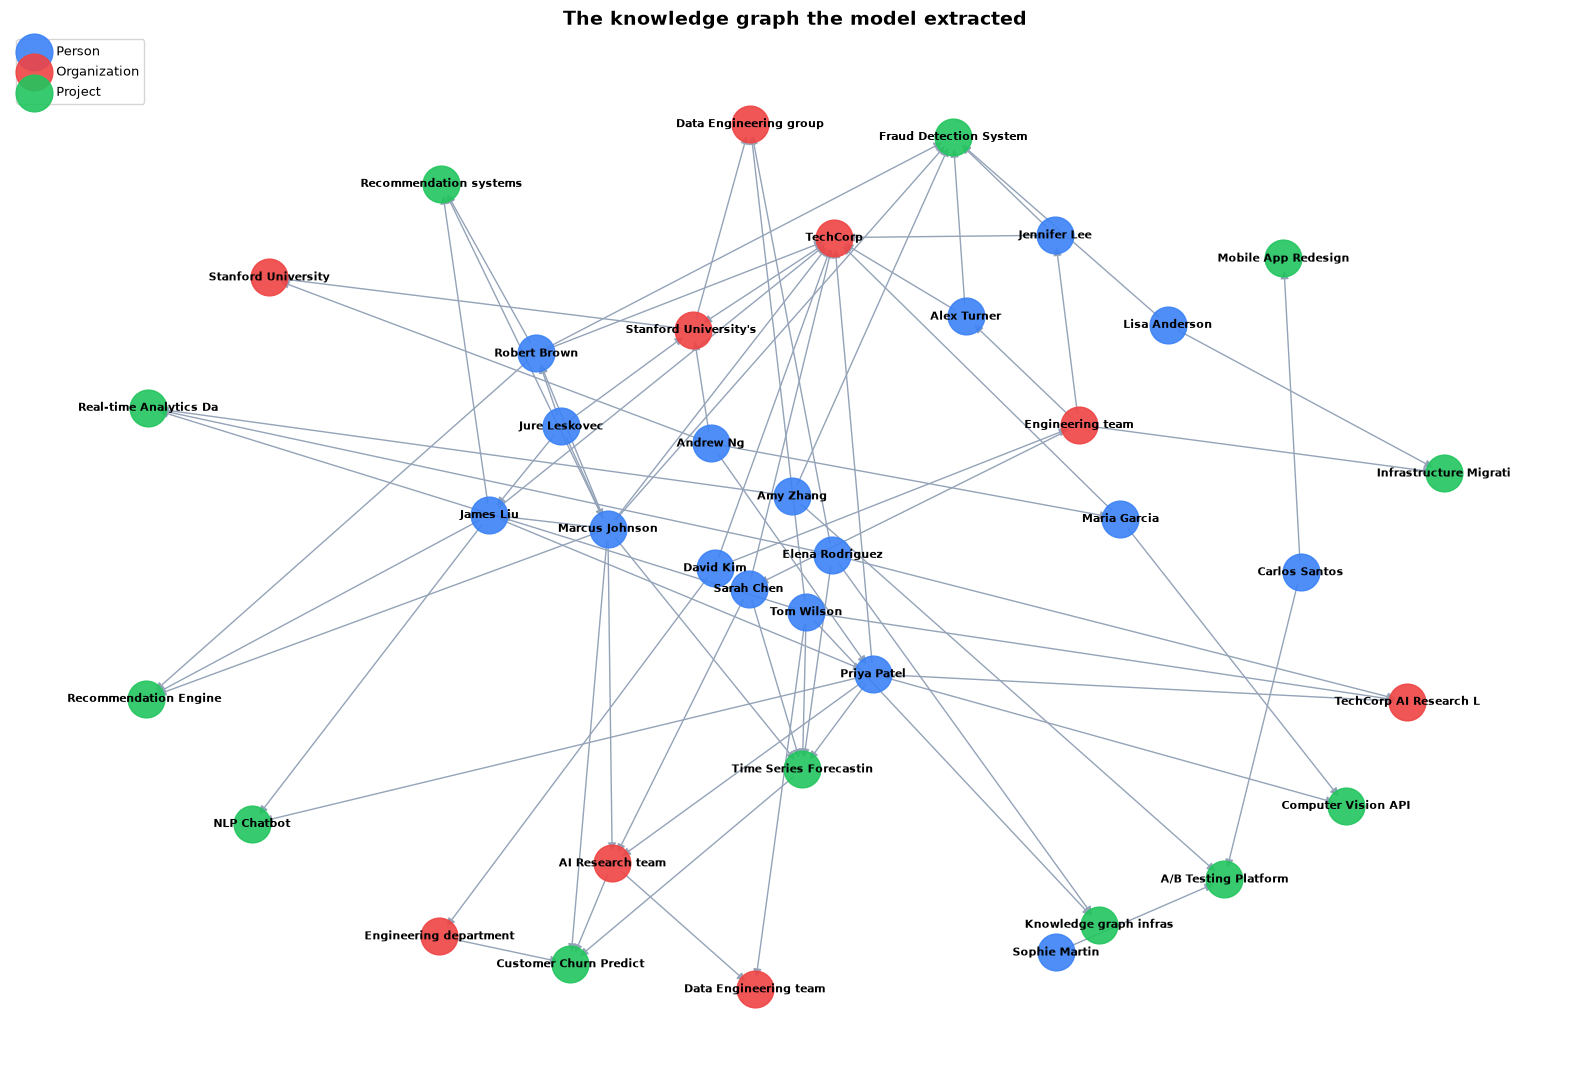

38 people, projects and organisations drawn; 74 relationships between them


In [8]:
COLORS = {"Person": "#3b82f6", "Organization": "#ef4444", "Project": "#22c55e", "Technology": "#f59e0b", "Event": "#a855f7"}

G = nx.DiGraph()
for row in run("MATCH (a)-[r]->(b) WHERE (a:Person OR a:Project OR a:Organization) AND (b:Person OR b:Project OR b:Organization) "
               "RETURN a.name AS a, labels(a)[0] AS la, type(r) AS t, b.name AS b, labels(b)[0] AS lb"):
    G.add_node(row["a"], label=row["la"]); G.add_node(row["b"], label=row["lb"]); G.add_edge(row["a"], row["b"], type=row["t"])

G.remove_nodes_from([n for n, deg in list(G.degree()) if deg < 2])     # drop leaves so the labels stay readable
pos = nx.spring_layout(G, k=2.4, iterations=300, seed=11)
plt.figure(figsize=(16, 11))
for label, color in COLORS.items():
    nodes = [n for n, d in G.nodes(data=True) if d.get("label") == label]
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=color, node_size=700, alpha=0.9, label=label)
nx.draw_networkx_edges(G, pos, edge_color="#94a3b8", arrows=True, arrowsize=12)
nx.draw_networkx_labels(G, pos, {n: n[:22] for n in G.nodes()}, font_size=8, font_weight="bold")
plt.title("The knowledge graph the model extracted", fontsize=14, fontweight="bold"); plt.legend(loc="upper left", fontsize=9); plt.axis("off"); plt.tight_layout(); plt.show()
print(G.number_of_nodes(), "people, projects and organisations drawn;", G.number_of_edges(), "relationships between them")


### 🔍 What just happened?

People cluster around the projects they share; Stanford and its professors sit on the edge, connected through the partnership. Nobody drew this by hand. It will not be perfect: the model may have missed an edge or invented a slightly wrong one, and in a real system you would review a sample. But it took seconds, and it scales to thousands of documents.


## 4.4 One question, three ways

### The vector side

The graph knows *structure*. The text still knows *detail*: accuracy numbers, dates, who said what. So the documents also go into a Chroma collection, embedded with OpenAI's model, exactly as in the ChromaDB module. Six documents, no chunking needed.


In [9]:
embed = embedding_functions.OpenAIEmbeddingFunction(api_key=api_key, model_name=EMBEDDING_MODEL)
chroma = chromadb.EphemeralClient()
collection = chroma.get_or_create_collection("company_docs", embedding_function=embed, configuration={"hnsw": {"space": "cosine"}})
collection.add(ids=[f"doc_{i}" for i in range(len(docs))], documents=[d["content"] for d in docs], metadatas=[{"title": d["title"]} for d in docs])

def vector_search(question, k=2):
    res = collection.query(query_texts=[question], n_results=k, include=["documents", "metadatas", "distances"])
    return [(m["title"], doc, dist) for m, doc, dist in zip(res["metadatas"][0], res["documents"][0], res["distances"][0])]

for title, _, dist in vector_search("Who works with Marcus Johnson on AI projects?", k=3):
    print(f"{dist:.3f}  {title}")


0.436  Q4 2024 AI Research Team Update
0.474  Fraud Detection System - Project Kickoff Notes
0.495  Recommendation Engine v2 - Technical Design


### Vector only, graph only, both together

The question: **"Who does Marcus Johnson work with, and on which projects?"** It is a relationship question, and Marcus is mentioned in five of the six documents, so it is a fair test. The three answerers share one helper that sends a context block to the model.


In [10]:
def answer(question, context):
    return client.responses.create(
        model=MODEL,
        input=("Answer the question using only the context below. Be specific and name people and projects.\n\n"
               f"CONTEXT:\n{context}\n\nQUESTION: {question}"),
    ).output_text

question = "Who does Marcus Johnson work with, and on which projects?"


In [11]:
# (a) Vector only: the two closest documents, nothing else. This is the RAG from the ChromaDB module.
hits = vector_search(question, k=2)
context_vec = "\n\n".join(f"[{title}]\n{doc}" for title, doc, _ in hits)

print("documents used:", [title for title, _, _ in hits], "\n")
print(answer(question, context_vec))


documents used: ['Fraud Detection System - Project Kickoff Notes', 'Recommendation Engine v2 - Technical Design'] 



Marcus Johnson is the technical lead on two projects:

- **Fraud Detection System:** He works with **Robert Brown** on model development, **Amy Zhang** on the API layer, and **Lisa Anderson** on AWS infrastructure. **James Liu** also attended the project kickoff.
- **Recommendation Engine v2:** He works with **James Liu**, an ML Engineer, and **Robert Brown**, a Senior Data Scientist.


In [12]:
# (b) Graph only: two hops out from Marcus (Marcus -> his projects and teams -> the other people on them), as triples. No prose at all.
def neighbourhood(name, hops=1):
    rows = run(f"""
        MATCH (a {{name: $name}})-[r*1..{hops}]-(b)
        WHERE NOT b:Document AND none(rel IN r WHERE type(rel) = "MENTIONED_IN")   // stay among entities, never walk through a document
        UNWIND r AS rel
        RETURN DISTINCT startNode(rel).name AS s, type(rel) AS t, endNode(rel).name AS o
    """, name=name)
    return [f"{r['s']} -[{r['t']}]-> {r['o']}" for r in rows]

triples = neighbourhood("Marcus Johnson", hops=2)
context_graph = "\n".join(triples)

print(len(triples), "triples, for example:", triples[:4], "\n")
print(answer(question, context_graph))


67 triples, for example: ['Marcus Johnson -[MEMBER_OF]-> AI Research team', 'Sarah Chen -[LEADS]-> AI Research team', 'Priya Patel -[MEMBER_OF]-> AI Research team', 'AI Research team -[COLLABORATES_WITH]-> Data Engineering team'] 



Marcus Johnson’s direct collaborators are:

- **James Liu** — They work together on **Recommendation Engine v2**; Marcus leads it and James works on it. Both are also listed as working on **Recommendation systems**.
- **Robert Brown** — They work together on **Recommendation Engine v2**. They are also both associated with the **Fraud Detection System** and **Recommendation systems**; Marcus leads the fraud project.
- **Jure Leskovec** — He collaborates with Marcus, though the context doesn’t name a specific shared project.
- **The Time Series Forecasting Approach** — Marcus collaborates with this project. **Priya Patel, Elena Rodriguez, and Tom Wilson** work on it, and **Sarah Chen** also collaborates with it.

Marcus’s other listed project is **Customer Churn Prediction**, which he works on; no specific collaborator on that project is named in the context.


In [13]:
# (c) GraphRAG: vectors find the entry documents, the graph walks out from the entities mentioned in them, the prompt carries both.
def graphrag(question, k=2, hops=1, show=True):
    hits = vector_search(question, k=k)                                       # 1. entry points from the text
    titles = [title for title, _, _ in hits]
    entities = [r["name"] for r in run(                                       # 2. entities mentioned in those documents
        "MATCH (e)-[:MENTIONED_IN]->(d:Document) WHERE d.title IN $titles RETURN DISTINCT e.name AS name", titles=titles)]
    named = [e for e in entities if e.lower() in question.lower()]            # 3. walk the graph: one hop from each of them,
    triples = sorted({t for name in entities for t in neighbourhood(name, hops)}  #    one hop further from those the question names
                     | {t for name in named for t in neighbourhood(name, hops + 1)})
    context = ("TEXT PASSAGES:\n" + "\n\n".join(f"[{t}]\n{doc}" for t, doc, _ in hits)
               + "\n\nRELATIONSHIPS FROM THE KNOWLEDGE GRAPH:\n" + "\n".join(triples))   # 4. one prompt, both kinds of context
    if show:
        print(f"documents used: {titles}\nentities found in them: {len(entities)} | named in the question: {named} | graph triples added: {len(triples)}\n")
    return answer(question, context)

print(graphrag(question))


documents used: ['Fraud Detection System - Project Kickoff Notes', 'Recommendation Engine v2 - Technical Design']
entities found in them: 34 | named in the question: ['Marcus Johnson'] | graph triples added: 81



Marcus Johnson’s explicit collaborators are **James Liu** and **Robert Brown**.

- On **Fraud Detection System**, Marcus is the technical lead; Robert develops the model, Amy Zhang builds the API layer, and Lisa Anderson manages AWS deployment.
- On **Recommendation Engine v2**, Marcus is technical lead and works with James Liu and Robert Brown.

Marcus is also listed as working on **Customer Churn Prediction**, **Recommendation systems**, and the **Time Series Forecasting Approach**.


### 🔍 What just happened?

Compare the three answers. The **vector-only** answer knows what the two closest documents say and nothing about the other four: two projects, with the detail of who does what on each. The **graph-only** answer walked the graph around Marcus, so it also finds his projects and colleagues from the other documents, but only as bare edges: no roles, no dates, no context. The **GraphRAG** answer starts from the same two documents as the first one, keeps their detail, and adds what the graph knows about Marcus beyond them. Look for a project in it that neither of the two retrieved documents mentions: that fact came from a document that was never retrieved as text.

Your answers will differ a little from run to run, because the extraction step is not deterministic. The pattern stays: text gives detail, the graph gives reach.

The trick is step 2: the `MENTIONED_IN` edges connect the retrieved *text* to the *graph*, so the two stores are not separate systems but two views of the same documents. Step 3 then walks one hop from every entity in those documents, and one hop further from the entities the question itself names. A wide walk from everything would flood the prompt with edges nobody asked about.

### 🎯 Mini-task

Ask a question that needs two hops: "Which people are connected to Stanford University, directly or through a colleague?" Run it through `graphrag(..., hops=2)` and through the vector-only path, and compare.


In [14]:
# YOUR CODE HERE


### Multi-hop, the graph's home turf

Some questions are pure structure: "people within two hops of Sarah Chen" is a chain of relationships, and a vector search would need one document that happens to mention the whole chain. In Cypher it is a variable-length path.


In [15]:
rows = run("""
MATCH path = (:Person {name: "Sarah Chen"})-[*1..2]-(other:Person)
WHERE other.name <> "Sarah Chen"
RETURN other.name AS name, min(length(path)) AS hops
ORDER BY hops, name
""")

for hops in (1, 2):
    print(f"{hops} hop(s):", ", ".join(r["name"] for r in rows if r["hops"] == hops) or "(nobody: in this graph people are linked through teams and projects)")


1 hop(s): (nobody: in this graph people are linked through teams and projects)
2 hop(s): Alex Turner, Amy Zhang, Andrew Ng, Carlos Santos, David Kim, Elena Rodriguez, James Liu, Jennifer Lee, Jure Leskovec, Lisa Anderson, Marcus Johnson, Maria Garcia, Mohammed Ali, Nina Williams, Priya Patel, Raj Sharma, Robert Brown, Sophie Martin, Tom Wilson, Yoshua Bengio


## What you take with you

- A language model plus a **small, fixed schema** turns prose into a graph; the schema and the name normalisation decide the graph's quality, not the model.
- `MERGE` deduplicates on load; `MENTIONED_IN` edges tie every entity back to the text it came from.
- **Vector search** finds passages that sound like the question; **graph traversal** finds what is connected to them; **GraphRAG** puts both in one prompt.
- Reach for GraphRAG when questions hop across documents and entities; stay with plain RAG when each answer lives in one passage. It is the simpler system, and simpler wins until it fails.

If you build this for real, the same pipeline exists ready-made: Neo4j's `neo4j-graphrag` package and LlamaIndex's `PropertyGraphIndex` do extraction, loading and hybrid retrieval with a few lines of configuration. Now you know what those lines do.

One more pattern you will meet: instead of our fixed `graphrag()` function, the model gets a tool that runs read-only Cypher and writes the query itself. Same graph, but the model decides how to walk it. Neo4j publishes an MCP server for exactly this.


In [16]:
driver.close()
